In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

# !wget $data -O data-week-3.csv

In [4]:
df = pd.read_csv('data-week-3.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.lower().str.strip().str.replace(' ', '_')

In [6]:
df.columns=df.columns.str.lower().str.replace(' ','_')
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [7]:
df.dtypes

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges         object
churn                object
dtype: object

In [8]:
df.totalcharges

0         29.85
1        1889.5
2        108.15
3       1840.75
4        151.65
         ...   
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: totalcharges, Length: 7043, dtype: object

In [9]:
tc=pd.to_numeric(df.totalcharges, errors='coerce')

In [10]:
df[tc.isnull()][['customerid','totalcharges']]

,customerid,totalcharges
488,4472-lvygi,
753,3115-czmzd,
936,5709-lvoeq,
1082,4367-nuyao,
1340,1371-dwpaz,
3331,7644-omvmy,
3826,3213-vvolg,
4380,2520-sgtta,
5218,2923-arzlg,
6670,4075-wkniu,


In [11]:
# df.churn.replace('no',0, inplace=True)
# df.churn.replace('yes',1, inplace=True)
# df.churn=df.churn.astype(int)
# df.head().T
df.churn=(df.churn=='yes').astype(int)
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [12]:
import sklearn
from sklearn.model_selection import train_test_split
df_full_train,df_test=train_test_split(df, test_size=0.2, random_state=1)
df_train,df_val=train_test_split(df_full_train, test_size=0.25, random_state=1)

In [13]:
len(df_train),len(df_val),len(df_test)

(4225, 1409, 1409)

In [14]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)


In [15]:
y_train=df_train.churn.values
y_val=df_val.churn.values
y_test=df_test.churn.values
del df_train['churn']
del df_val['churn']
del df_test['churn']

In [16]:
df_full_train=df_full_train.reset_index(drop=True)
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [17]:
global_churn=df_full_train.churn.mean()
global_churn_rate=round(global_churn,2)

In [18]:
df_full_train.dtypes

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges         object
churn                 int64
dtype: object

In [117]:
numerical=['tenure','monthlycharges', 'seniorcitizen']
category=[ 'gender', 'partner', 'dependents',
        'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod']
ci=[i for i in df.select_dtypes('int64') + df.select_dtypes('float64')]
ci
ci.remove('churn')
ci

['monthlycharges', 'seniorcitizen', 'tenure']

In [20]:
df_full_train.gender


0         male
1       female
2         male
3         male
4         male
         ...  
5629      male
5630      male
5631      male
5632      male
5633    female
Name: gender, Length: 5634, dtype: object

In [21]:
df_full_train[category].nunique()

gender              2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

In [22]:
global_churn=df_full_train.churn.mean()
global_churn
female_churn=df_full_train[df_full_train.gender=='female'].churn.mean()
male_churn=df_full_train[df_full_train.gender=='male'].churn.mean()
partner_churn=df_full_train[df_full_train.partner=='yes'].churn.mean()
partner_no_churn=df_full_train[df_full_train.partner=='no'].churn.mean()
global_churn,female_churn,male_churn,partner_churn,partner_no_churn

(np.float64(0.26996805111821087),
 np.float64(0.27682403433476394),
 np.float64(0.2632135306553911),
 np.float64(0.20503330866025166),
 np.float64(0.3298090040927694))

In [23]:
global_churn-female_churn,global_churn-male_churn,global_churn-partner_churn,global_churn-partner_no_churn

(np.float64(-0.006855983216553063),
 np.float64(0.006754520462819769),
 np.float64(0.06493474245795922),
 np.float64(-0.05984095297455855))

In [24]:
global_churn/female_churn,global_churn/male_churn,global_churn/partner_churn,global_churn/partner_no_churn

(np.float64(0.975233424969661),
 np.float64(1.0256617524410743),
 np.float64(1.3167033828906243),
 np.float64(0.8185587651278121))

In [25]:
from IPython.display import display

In [120]:
for c in category:
    print(c)
    df_group= df_full_train.groupby(c).churn.agg(['mean','count','sum'])
    df_group['diff']=df_group['mean']-global_churn
    df_group['risk']=df_group['mean']/global_churn
    display(df_group)

gender


,mean,count,sum,diff,risk
gender,,,,,
female,0.276824,2796,774,0.006856,1.025396
male,0.263214,2838,747,-0.006755,0.974980


partner


,mean,count,sum,diff,risk
partner,,,,,
no,0.329809,2932,967,0.059841,1.221659
yes,0.205033,2702,554,-0.064935,0.759472


dependents


,mean,count,sum,diff,risk
dependents,,,,,
no,0.313760,3968,1245,0.043792,1.162212
yes,0.165666,1666,276,-0.104302,0.613651


... (20 outputs left out)

paperlessbilling


,mean,count,sum,diff,risk
paperlessbilling,,,,,
no,0.172071,2313,398,-0.097897,0.637375
yes,0.338151,3321,1123,0.068183,1.252560


paymentmethod


,mean,count,sum,diff,risk
paymentmethod,,,,,
bank_transfer_(automatic),0.168171,1219,205,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,200,-0.105630,0.608733
electronic_check,0.455890,1893,863,0.185922,1.688682
mailed_check,0.193870,1305,253,-0.076098,0.718121


In [27]:
from sklearn.metrics import mutual_info_score

In [119]:
opo=0
for c in category:
    print(c)
    display(mutual_info_score(df_full_train[c],df_full_train.churn))
    opo=max(opo,mutual_info_score(df_full_train[c],df_full_train.churn))

opo

gender


0.0001174846211139946

partner


0.009967689095399745

dependents


0.012345815445534689

... (21 outputs left out)

0.01758882715925275

paymentmethod


0.043210027531582915

0.0983203874041556

In [29]:
def mutual_info_churn_score(series):
    return mutual_info_score(series,df_full_train.churn)

In [30]:
mi=df_full_train[category].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

In [31]:
df_full_train.tenure.max()

np.int64(72)

In [32]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
seniorcitizen     0.141966
dtype: float64

In [33]:
df_full_train[df_full_train.tenure <=2].churn.mean()

np.float64(0.5953420669577875)

In [34]:
df_full_train[(df_full_train.tenure >2) & (df_full_train.tenure <=12)].churn.mean() 

np.float64(0.3994413407821229)

In [35]:
df_full_train[df_full_train.tenure >12].churn.mean()

np.float64(0.17634908339788277)

In [36]:
df_full_train[df_full_train.monthlycharges > 5].tenure.mean()

np.float64(32.277955271565496)

In [37]:
from sklearn.feature_extraction import DictVectorizer
train_dicts=df_train[category+numerical].to_dict(orient='records')
val_dicts=df_val[category+numerical].to_dict(orient='records')
test_dicts=df_test[category+numerical].to_dict(orient='records')

train_dicts

[{'gender': 'female',
  'partner': 'yes',
  'dependents': 'yes',
  'phoneservice': 'yes',
  'multiplelines': 'yes',
  'internetservice': 'fiber_optic',
  'onlinesecurity': 'yes',
  'onlinebackup': 'yes',
  'deviceprotection': 'yes',
  'techsupport': 'yes',
  'streamingtv': 'yes',
  'streamingmovies': 'yes',
  'contract': 'two_year',
  'paperlessbilling': 'yes',
  'paymentmethod': 'electronic_check',
  'tenure': 72,
  'monthlycharges': 115.5,
  'seniorcitizen': 0},
 {'gender': 'male',
  'partner': 'no',
  'dependents': 'no',
  'phoneservice': 'yes',
  'multiplelines': 'yes',
  'internetservice': 'fiber_optic',
  'onlinesecurity': 'no',
  'onlinebackup': 'yes',
  'deviceprotection': 'yes',
  'techsupport': 'no',
  'streamingtv': 'no',
  'streamingmovies': 'yes',
  'contract': 'month-to-month',
  'paperlessbilling': 'yes',
  'paymentmethod': 'electronic_check',
  'tenure': 10,
  'monthlycharges': 95.25,
  'seniorcitizen': 0},
 {'gender': 'female',
  'partner': 'no',
  'dependents': 'no',


In [38]:
dv=DictVectorizer(sparse=False)

In [39]:
X_train=dv.fit_transform(train_dicts)
X_val=dv.transform(val_dicts)
X_test=dv.transform(test_dicts)

In [40]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [41]:
X_train.shape,X_test.shape,X_val.shape

((4225, 44), (1409, 44), (1409, 44))

In [42]:
X_train[0],dv.get_feature_names_out()

(array([  0. ,   0. ,   1. ,   0. ,   1. ,   0. ,   0. ,   1. ,   1. ,
          0. ,   0. ,   1. ,   0. , 115.5,   0. ,   0. ,   1. ,   0. ,
          0. ,   1. ,   0. ,   0. ,   1. ,   0. ,   1. ,   0. ,   1. ,
          0. ,   0. ,   1. ,   0. ,   0. ,   1. ,   0. ,   0. ,   0. ,
          1. ,   0. ,   0. ,   1. ,   0. ,   0. ,   1. ,  72. ]),
 array(['contract=month-to-month', 'contract=one_year',
        'contract=two_year', 'dependents=no', 'dependents=yes',
        'deviceprotection=no', 'deviceprotection=no_internet_service',
        'deviceprotection=yes', 'gender=female', 'gender=male',
        'internetservice=dsl', 'internetservice=fiber_optic',
        'internetservice=no', 'monthlycharges', 'multiplelines=no',
        'multiplelines=no_phone_service', 'multiplelines=yes',
        'onlinebackup=no', 'onlinebackup=no_internet_service',
        'onlinebackup=yes', 'onlinesecurity=no',
        'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
        'paperlessbill

In [43]:
import numpy as np
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [44]:
z=np.linspace(-5,5,51)
print(sigmoid(z))

[0.00669285 0.00816257 0.0099518  0.01212843 0.01477403 0.01798621
 0.02188127 0.02659699 0.03229546 0.03916572 0.04742587 0.05732418
 0.06913842 0.0831727  0.09975049 0.11920292 0.14185106 0.16798161
 0.19781611 0.23147522 0.26894142 0.31002552 0.35434369 0.40131234
 0.450166   0.5        0.549834   0.59868766 0.64565631 0.68997448
 0.73105858 0.76852478 0.80218389 0.83201839 0.85814894 0.88079708
 0.90024951 0.9168273  0.93086158 0.94267582 0.95257413 0.96083428
 0.96770454 0.97340301 0.97811873 0.98201379 0.98522597 0.98787157
 0.9900482  0.99183743 0.99330715]


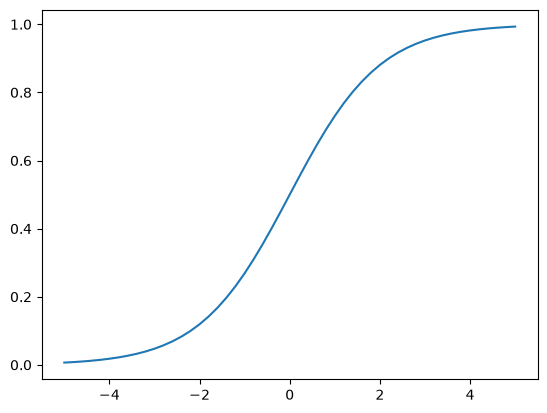

In [45]:
plt.plot(z,sigmoid(z))
plt.show()

In [46]:
xi=[2,7.596392,6,238.0,4070,17.9]
w0=2
w=[0.1,0.001,0.004,0.023,0.04,0.00001]
w_new=[w0]+w
w_new

[2, 0.1, 0.001, 0.004, 0.023, 0.04, 1e-05]

In [47]:
def linear_manual_regresstion(xi):
    result=w0

    for j in range(len(w)):
        result=result+xi[j] * w[j]

    return result

In [48]:
def logistic_manual_regression(xi):
   score=0
   for i in range(len(w)):
      score=score+ xi[i] * w[i]
   result= sigmoid(score)
   return result

In [49]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train,y=y_train)

/home/mohamed/mlops_project/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [50]:
model.coef_[0].round(3)

array([ 0.593, -0.068, -0.695, -0.057, -0.113,  0.018, -0.123, -0.065,
       -0.066, -0.104, -0.411,  0.364, -0.123,  0.007, -0.265,  0.084,
        0.01 ,  0.021, -0.123, -0.068,  0.184, -0.123, -0.231, -0.267,
        0.097, -0.15 , -0.02 , -0.126, -0.08 ,  0.048, -0.012,  0.084,
       -0.255,  0.201, -0.138, -0.123,  0.091, -0.105, -0.123,  0.058,
        0.14 , -0.123, -0.187, -0.037])

In [51]:
model.intercept_[0]

np.float64(-0.17665724038560257)

In [52]:
y_pred=model.predict_proba(X_val)[:,1]
churn_decision=(y_pred >=0.5)

In [ ]:
df_val[churn_decision].customerid

3       8433-wxgna
8       3440-jpscl
12      7228-omtpn
19      6711-fldfb
24      2612-ranwt
           ...    
1397    5976-jcjrh
1398    2034-cgrhz
1399    5276-kqwhg
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 304, dtype: object

In [54]:
(y_val == churn_decision).mean()

np.float64(0.8055358410220014)

In [55]:
df_pred=pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction']= churn_decision.astype(int)
df_pred['actual']=y_val


In [56]:
df_pred['correct']= df_pred.prediction ==df_pred.actual

In [57]:
df_pred.correct.mean()

np.float64(0.8055358410220014)

In [58]:
dict(zip(dv.get_feature_names_out(),model.coef_[0].round(3)))

{'contract=month-to-month': np.float64(0.593),
 'contract=one_year': np.float64(-0.068),
 'contract=two_year': np.float64(-0.695),
 'dependents=no': np.float64(-0.057),
 'dependents=yes': np.float64(-0.113),
 'deviceprotection=no': np.float64(0.018),
 'deviceprotection=no_internet_service': np.float64(-0.123),
 'deviceprotection=yes': np.float64(-0.065),
 'gender=female': np.float64(-0.066),
 'gender=male': np.float64(-0.104),
 'internetservice=dsl': np.float64(-0.411),
 'internetservice=fiber_optic': np.float64(0.364),
 'internetservice=no': np.float64(-0.123),
 'monthlycharges': np.float64(0.007),
 'multiplelines=no': np.float64(-0.265),
 'multiplelines=no_phone_service': np.float64(0.084),
 'multiplelines=yes': np.float64(0.01),
 'onlinebackup=no': np.float64(0.021),
 'onlinebackup=no_internet_service': np.float64(-0.123),
 'onlinebackup=yes': np.float64(-0.068),
 'onlinesecurity=no': np.float64(0.184),
 'onlinesecurity=no_internet_service': np.float64(-0.123),
 'onlinesecurity=yes'

In [59]:
small=['contract','tenure','monthlycharges']
df_train[small].iloc[:10].to_dict(orient='records')

[{'contract': 'two_year', 'tenure': 72, 'monthlycharges': 115.5},
 {'contract': 'month-to-month', 'tenure': 10, 'monthlycharges': 95.25},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 75.55},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 80.85},
 {'contract': 'two_year', 'tenure': 18, 'monthlycharges': 20.1},
 {'contract': 'month-to-month', 'tenure': 4, 'monthlycharges': 30.5},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 75.1},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 70.3},
 {'contract': 'two_year', 'tenure': 72, 'monthlycharges': 19.75},
 {'contract': 'month-to-month', 'tenure': 6, 'monthlycharges': 109.9}]

In [60]:
dv_small=DictVectorizer()
dicts_train_small=df_train[small].to_dict(orient='records')
dicts_val_small=df_val[small].to_dict(orient='records')
dv_small.fit(dicts_train_small)
dv_small.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'monthlycharges', 'tenure'], dtype=object)

In [61]:
X_train_small=dv_small.transform(dicts_train_small)
X_val_small=dv_small.transform(dicts_val_small)
X_train_small.shape,y_train.shape

((4225, 5), (4225,))

In [62]:
model_small=LogisticRegression()
model_small.fit(X_train_small,y_train)
y_pred=model_small.predict(X_val_small)
(y_pred==y_val).mean()

np.float64(0.7963094393186657)

In [63]:
w0=model_small.intercept_[0]
w0
w=model_small.coef_[0].round(3)
w,w0

(array([ 0.971, -0.024, -0.948,  0.027, -0.036]),
 np.float64(-2.4779575943972962))

In [64]:
dict(zip(dv_small.get_feature_names_out(),w))

{'contract=month-to-month': np.float64(0.971),
 'contract=one_year': np.float64(-0.024),
 'contract=two_year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

In [65]:
y=df_full_train.churn.values
y

array([0, 1, 0, ..., 1, 1, 0], shape=(5634,))

In [66]:
dicts_full_train=df_full_train[category+numerical].to_dict(orient='records')
dv=DictVectorizer(sparse=False)
X_fill_train=dv.fit_transform(dicts_full_train)
model=LogisticRegression().fit(X_fill_train,y)


/home/mohamed/mlops_project/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [67]:
dicts_test=df_test[category+numerical].to_dict(orient='records')
X_test=dv.fit_transform(dicts_test)


In [68]:
y_pred=model.predict_proba(X_test)[:,1]
y_true=df.churn.values


In [69]:
churn_decision=(y_pred >=0.5)
churn_decision

array([False, False, False, ..., False, False,  True], shape=(1409,))

In [70]:
(churn_decision==y_test).mean()

np.float64(0.8069552874378992)

In [71]:
dicts=df[category+numerical].to_dict(orient='records')
X=dv.fit_transform(dicts)
y_predd=model.predict_proba(X)[:,1]
churn_decisions=(y_predd >=0.5)
(churn_decisions==y_true).mean()

np.float64(0.8039187846088315)

In [72]:
dicts_val=df_val[category+numerical].to_dict(orient='records')
X_val=dv.fit_transform(dicts_val)
model.fit(X_train,y_train)
y_pred=model.predict_proba(X_val)[:,1]
y_pred
churn_decision=(y_pred >=0.5)
(y_val == churn_decision).mean()



/home/mohamed/mlops_project/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


np.float64(0.8055358410220014)

In [73]:
(y_val == churn_decision).sum(),len(y_val)


(np.int64(1135), 1409)

0.00 0.274
0.05 0.507
0.10 0.598
0.15 0.663
0.20 0.718
0.25 0.746
0.30 0.759
0.35 0.766
0.40 0.780
0.45 0.798
0.50 0.806
0.55 0.803
0.60 0.797
0.65 0.793
0.70 0.770
0.75 0.745
0.80 0.736
0.85 0.727
0.90 0.726
0.95 0.726
1.00 0.726


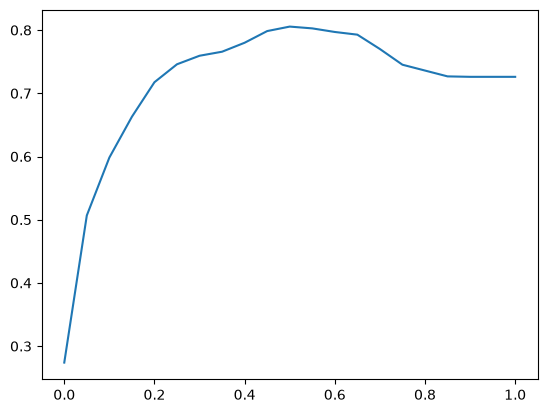

In [74]:
from sklearn.metrics import accuracy_score
thresholds=np.linspace(0,1,21)
scores=[]

for t in thresholds:
    score=accuracy_score(y_val,y_pred >= t)
    # churn_decision=(y_pred >= t)
    # score= (y_val==churn_decision).mean()
    print('%.2f %.3f'%(t,score))
    scores.append(score)
plt.plot(thresholds,scores)

In [75]:
from collections import Counter
Counter(y_pred >=1.0)

Counter({np.False_: 1409})

In [76]:
(y_pred >=0.5).mean()

np.float64(0.2157558552164656)

In [77]:
1-y_val.mean()

np.float64(0.7260468417317246)

In [78]:
actual_positive=(y_val == 1)
actual_negative=(y_val == 0)

In [79]:
t=0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [80]:
actual_positive.mean() , actual_negative.mean() , predict_negative.mean(),predict_positive.mean()

(np.float64(0.2739531582682754),
 np.float64(0.7260468417317246),
 np.float64(0.7842441447835344),
 np.float64(0.2157558552164656))

In [81]:
tp=(predict_positive & actual_positive).sum()
tn=(actual_negative & predict_negative).sum()

In [82]:
fp=(predict_positive & actual_negative).sum()
fn=(predict_negative & actual_positive).sum()

In [83]:
tp,tn,fp,fn

(np.int64(208), np.int64(927), np.int64(96), np.int64(178))

In [84]:
cofustion_matrix=np.array([
    [tn,fp],
    [fn,tp]
])

In [85]:
cofustion_matrix

array([[927,  96],
       [178, 208]])

In [86]:
((cofustion_matrix / cofustion_matrix.sum())).round(2)

array([[0.66, 0.07],
       [0.13, 0.15]])

In [87]:
recal=tp/(tp+fn)
recal

np.float64(0.538860103626943)

In [88]:
pre=tp/(tp+fp)
pre

np.float64(0.6842105263157895)

In [89]:
tpr=tp/(tp+fp)
fpr=fp/(tn+fp)
fpr,tpr

(np.float64(0.093841642228739), np.float64(0.6842105263157895))

In [90]:
scores=[]
thresholds= np.linspace(0,1,101)
for t in thresholds:
    actual_positive= (y_val == 1)
    actual_negative= (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp=(predict_positive & actual_positive).sum()
    tn=(actual_negative & predict_negative).sum()
    fp=(predict_positive & actual_negative).sum()
    fn=(predict_negative & actual_positive).sum()

    scores.append((t,tp,fp,fn,tn))

In [91]:
columns=['thresholds','tp','fp','fn','tn']
df_scores=pd.DataFrame(scores,columns=columns)
df_scores[::10]

,thresholds,tp,fp,fn,tn
0,0.0,386,1023,0,0
10,0.1,369,549,17,474
20,0.2,331,343,55,680
30,0.3,289,242,97,781
40,0.4,246,170,140,853
50,0.5,208,96,178,927
60,0.6,153,53,233,970
70,0.7,82,20,304,1003
80,0.8,14,0,372,1023
90,0.9,0,0,386,1023


In [92]:
df_scores['tpr']=df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr']=df_scores.fp / (df_scores.fp + df_scores.tn)

In [93]:
df_scores[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,369,549,17,474,0.955959,0.536657
20,0.2,331,343,55,680,0.857513,0.335288
30,0.3,289,242,97,781,0.748705,0.236559
40,0.4,246,170,140,853,0.637306,0.166178
50,0.5,208,96,178,927,0.538860,0.093842
60,0.6,153,53,233,970,0.396373,0.051808
70,0.7,82,20,304,1003,0.212435,0.019550
80,0.8,14,0,372,1023,0.036269,0.000000
90,0.9,0,0,386,1023,0.000000,0.000000


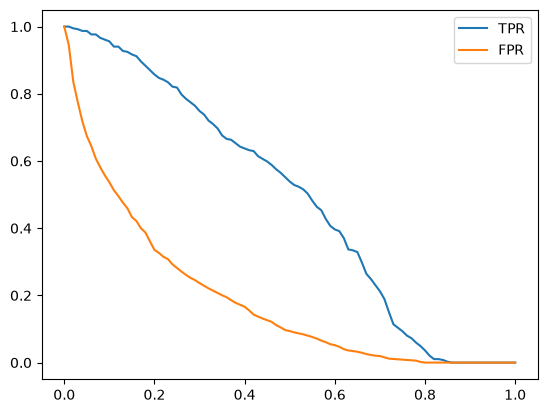

In [94]:
plt.plot(df_scores.thresholds , df_scores.tpr,label='TPR')
plt.plot(df_scores.thresholds , df_scores.fpr,label='FPR')
plt.legend()

In [95]:
np.random.seed(1)
y_rand= np.random.uniform(0,1,size=len(y_val))


In [96]:
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

In [97]:
def tpr_fpr_dataframe(y_val,y_pred):
    scores=[]
    thresholds= np.linspace(0,1,101)
    for t in thresholds:
        actual_positive= (y_val == 1)
        actual_negative= (y_val == 0)
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp=(predict_positive & actual_positive).sum()
        tn=(actual_negative & predict_negative).sum()
        fp=(predict_positive & actual_negative).sum()
        fn=(predict_negative & actual_positive).sum()

        scores.append((t,tp,fp,fn,tn))
    columns=['thresholds','tp','fp','fn','tn']
    df_scores=pd.DataFrame(scores,columns=columns)
    df_scores[::10]
    df_scores['tpr']=df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr']=df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores


In [98]:
df_rand= tpr_fpr_dataframe(y_val=y_val,y_pred=y_rand)
df_rand[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


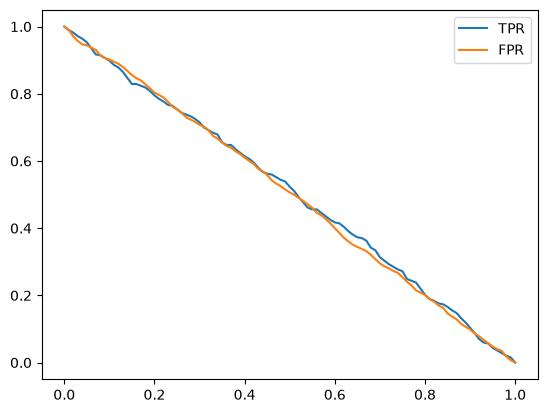

In [99]:
plt.plot(df_rand.thresholds , df_rand.tpr,label='TPR')
plt.plot(df_rand.thresholds , df_rand.fpr,label='FPR')
plt.legend()

In [100]:
num_pos=(y_val ==1).sum()
num_neg=(y_val ==0).sum()
num_pos , num_neg

(np.int64(386), np.int64(1023))

In [104]:
y_ideal=np.repeat([0,1],[num_neg,num_pos])
y_ideal[::100],y_val[::100]

(array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1]),
 array([0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0]))

In [105]:
y_ideal_pred=np.linspace(0,1,len(y_val))
y_ideal_pred

array([0.00000000e+00, 7.10227273e-04, 1.42045455e-03, ...,
       9.98579545e-01, 9.99289773e-01, 1.00000000e+00], shape=(1409,))

In [107]:
1-y_val.mean()

np.float64(0.7260468417317246)

In [109]:
((y_ideal_pred >=0.726) == y_ideal).mean()

np.float64(1.0)

In [112]:
df_ideal=tpr_fpr_dataframe(y_val=y_val,y_pred=y_ideal_pred)
df_ideal[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,348,920,38,103,0.901554,0.899316
20,0.2,306,821,80,202,0.792746,0.802542
30,0.3,268,718,118,305,0.694301,0.701857
40,0.4,233,612,153,411,0.603627,0.598240
50,0.5,190,515,196,508,0.492228,0.503421
60,0.6,152,412,234,611,0.393782,0.402737
70,0.7,115,308,271,715,0.297927,0.301075
80,0.8,73,209,313,814,0.189119,0.204301
90,0.9,40,101,346,922,0.103627,0.098729


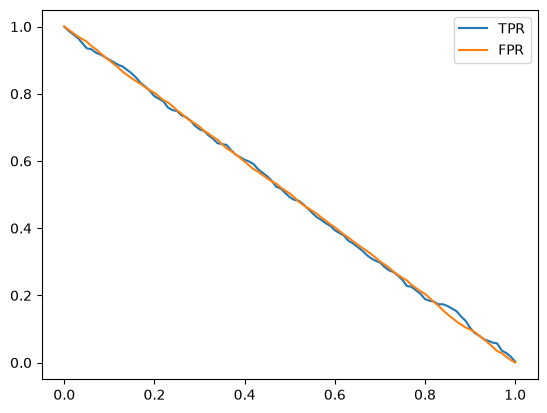

In [113]:
plt.plot(df_ideal.thresholds , df_ideal.tpr,label='TPR')
plt.plot(df_ideal.thresholds , df_ideal.fpr,label='FPR')
plt.legend()

In [114]:
df_ideal=tpr_fpr_dataframe(y_val=y_ideal,y_pred=y_ideal_pred)
df_ideal[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


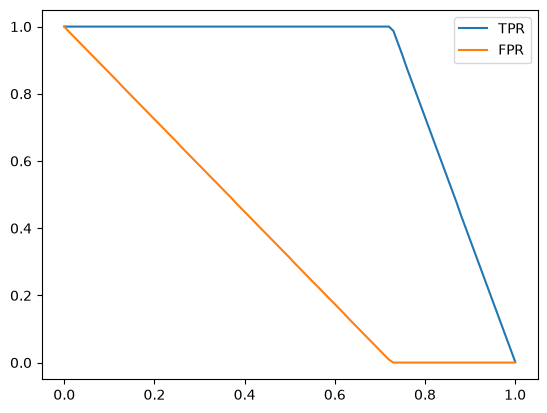

In [115]:
plt.plot(df_ideal.thresholds , df_ideal.tpr,label='TPR')
plt.plot(df_ideal.thresholds , df_ideal.fpr,label='FPR')
plt.legend()

In [121]:
from sklearn.metrics import roc_curve
fpr,tpr,thresholds = roc_curve(y_val,y_pred)

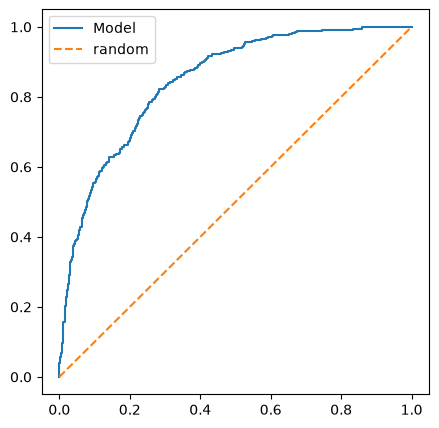

In [123]:
plt.figure(figsize=(5,5))
plt.plot(fpr,tpr, label="Model")
plt.plot([0,1],[0,1],label='random',linestyle='--')
plt.legend()

In [124]:
from sklearn.metrics import auc
auc(fpr,tpr)

0.845618140286367